In [1]:
from sklearn.metrics import roc_auc_score
import player_performance_prototype as p

matches = p.load_match_payloads(p.discover_recent_json_files())
df = p.build_model_frame(p.flatten_players(matches))
df = df[df.teamPosition.isin(["TOP", "JUNGLE", "MIDDLE", "BOTTOM", "UTILITY"])]
print("all", roc_auc_score(df.win, df.performance_score))
for role, g in df.groupby("teamPosition"):
    print(role, roc_auc_score(g.win, g.performance_score))

all 0.7743416554035591
BOTTOM 0.7929991910914629
JUNGLE 0.818178377092071
MIDDLE 0.7636043427495426
TOP 0.7575078551239318
UTILITY 0.7394037231917501


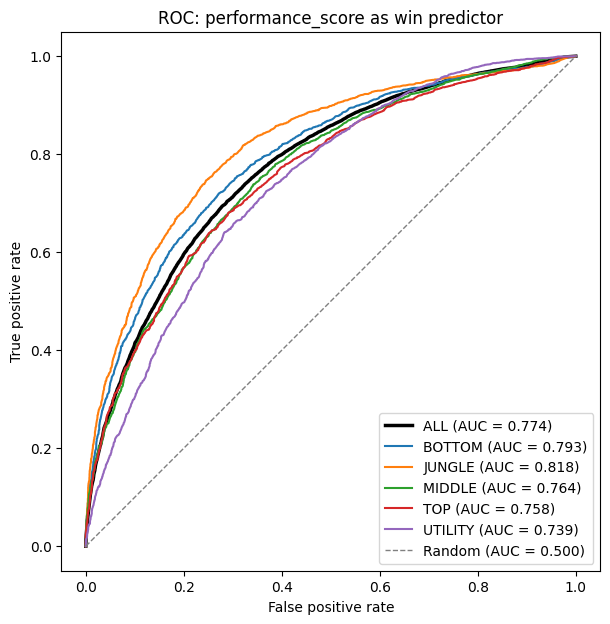

In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(7, 7))
fpr, tpr, _ = roc_curve(df.win, df.performance_score)
ax.plot(fpr, tpr, color="black", lw=2.5, label=f"ALL (AUC = {roc_auc_score(df.win, df.performance_score):.3f})")
for role, g in df.groupby("teamPosition"):
    fpr, tpr, _ = roc_curve(g.win, g.performance_score)
    ax.plot(fpr, tpr, lw=1.5, label=f"{role} (AUC = {roc_auc_score(g.win, g.performance_score):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="Random (AUC = 0.500)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC: performance_score as win predictor")
ax.set_aspect("equal")
ax.legend(loc="lower right")
fig.savefig(p.OUTPUT_DIR / "roc_curves.png", dpi=160, bbox_inches="tight")
plt.show()